# End-to-End Machine Learning Pipeline for Automobile Price Prediction

**Goal:** Build a robust, accurate, and well-generalized regression model that predicts a car's `price` from its technical and categorical specifications.

**Pipeline stages**
1. Data Loading & Overview
2. Exploratory Data Analysis (EDA)
3. Data Cleaning
4. Feature Engineering
5. Preprocessing Pipeline (`ColumnTransformer`)
6. Model Selection (cross-validated comparison of 11 algorithms)
7. Hyperparameter Tuning (`GridSearchCV`)
8. Final Evaluation on a held-out test set
9. Feature Importance
10. Model Export (`joblib`)


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor,BaggingRegressor,ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
print('Libraries loaded.')

Libraries loaded.


## 1. Data Loading

The raw CSV has **no header row**, and missing values are encoded as `'?'`. We assign the standard UCI column names and parse `'?'` as `NaN`.

In [2]:
column_names = [
    'symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration', 'num_doors',
    'body_style', 'drive_wheels', 'engine_location', 'wheel_base', 'length', 'width',
    'height', 'curb_weight', 'engine_type', 'num_cylinders', 'engine_size', 'fuel_system',
    'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg',
    'highway_mpg', 'price'
]

df = pd.read_csv('auto_imports.csv', header=None, names=column_names, na_values='?')

# price is the target -> rows without a price are useless for supervised learning
df = df.dropna(subset=['price']).reset_index(drop=True)

print('Shape:', df.shape)
df.head()

Shape: (201, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               201 non-null    object 
 3   fuel_type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num_doors          199 non-null    object 
 6   body_style         201 non-null    object 
 7   drive_wheels       201 non-null    object 
 8   engine_location    201 non-null    object 
 9   wheel_base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb_weight        201 non-null    int64  
 14  engine_type        201 non-null    object 
 15  num_cylinders      201 non-null    object 
 16  engine_size        201 non

## 2. Exploratory Data Analysis (EDA)

We examine missing values, summary statistics, the target distribution, correlations between numeric
features and `price`, and how categorical features relate to `price`.

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
normalized_losses,37,18.41
bore,4,1.99
stroke,4,1.99
num_doors,2,1.00
horsepower,2,1.00
peak_rpm,2,1.00


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.840796,1.254802,-2.00,0.00,1.00,2.00,3.00
normalized_losses,164.0,122.000000,35.442168,65.00,94.00,115.00,150.00,256.00
wheel_base,201.0,98.797015,6.066366,86.60,94.50,97.00,102.40,120.90
length,201.0,174.200995,12.322175,141.10,166.80,173.20,183.50,208.10
width,201.0,65.889055,2.101471,60.30,64.10,65.50,66.60,72.00
height,201.0,53.766667,2.447822,47.80,52.00,54.10,55.50,59.80
curb_weight,201.0,2555.666667,517.296727,1488.00,2169.00,2414.00,2926.00,4066.00
engine_size,201.0,126.875622,41.546834,61.00,98.00,120.00,141.00,326.00
bore,197.0,3.330711,0.270793,2.54,3.15,3.31,3.59,3.94
stroke,197.0,3.256904,0.319256,2.07,3.11,3.29,3.41,4.17


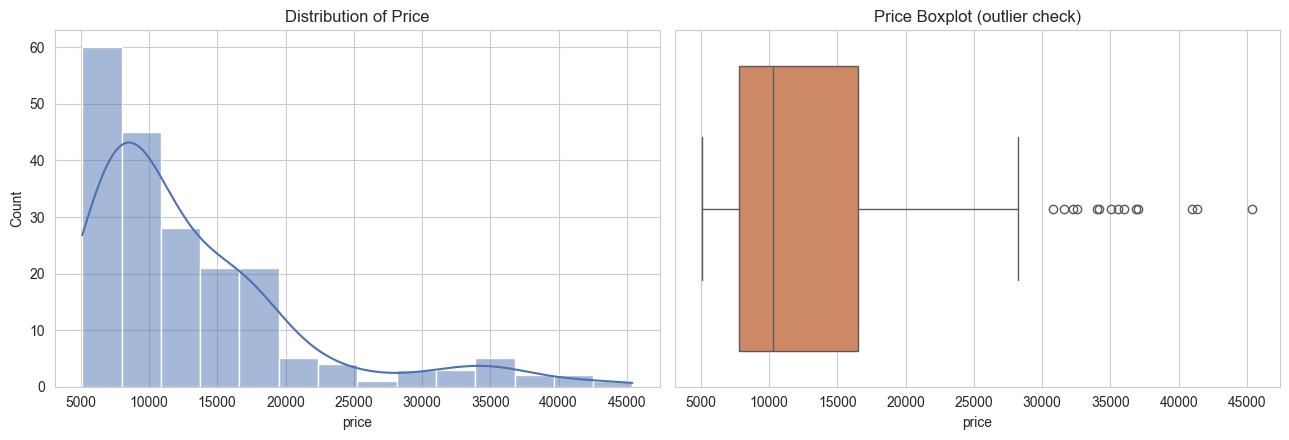

Skewness of price: 1.81


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['price'], kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Distribution of Price')
sns.boxplot(x=df['price'], ax=axes[1], color='#DD8452')
axes[1].set_title('Price Boxplot (outlier check)')
plt.tight_layout()
plt.show()
print('Skewness of price:', round(df['price'].skew(), 3))

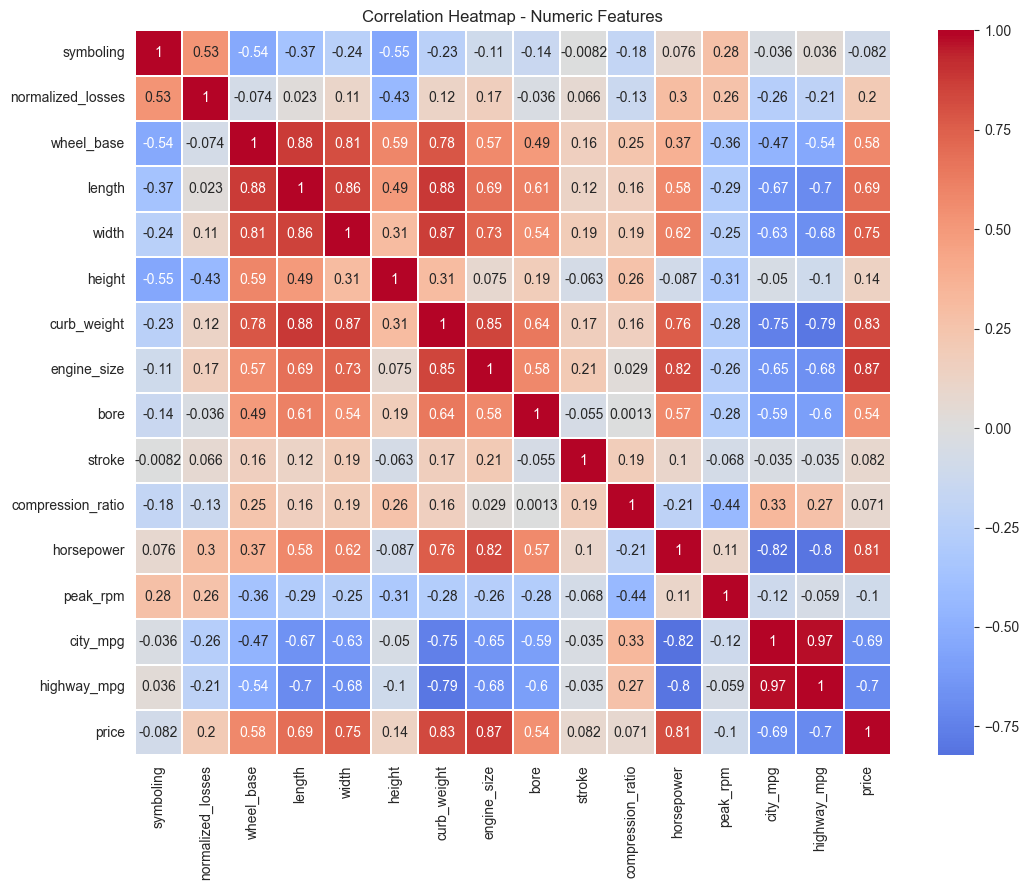

engine_size          0.872335
curb_weight          0.834415
horsepower           0.810533
width                0.751265
length               0.690628
wheel_base           0.584642
bore                 0.543436
normalized_losses    0.203254
height               0.135486
stroke               0.082310
compression_ratio    0.071107
symboling           -0.082391
peak_rpm            -0.101649
city_mpg            -0.686571
highway_mpg         -0.704692
Name: price, dtype: float64

In [7]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, linewidths=0.3)
plt.title('Correlation Heatmap - Numeric Features')
plt.tight_layout()
plt.show()

corr['price'].drop('price').sort_values(ascending=False)

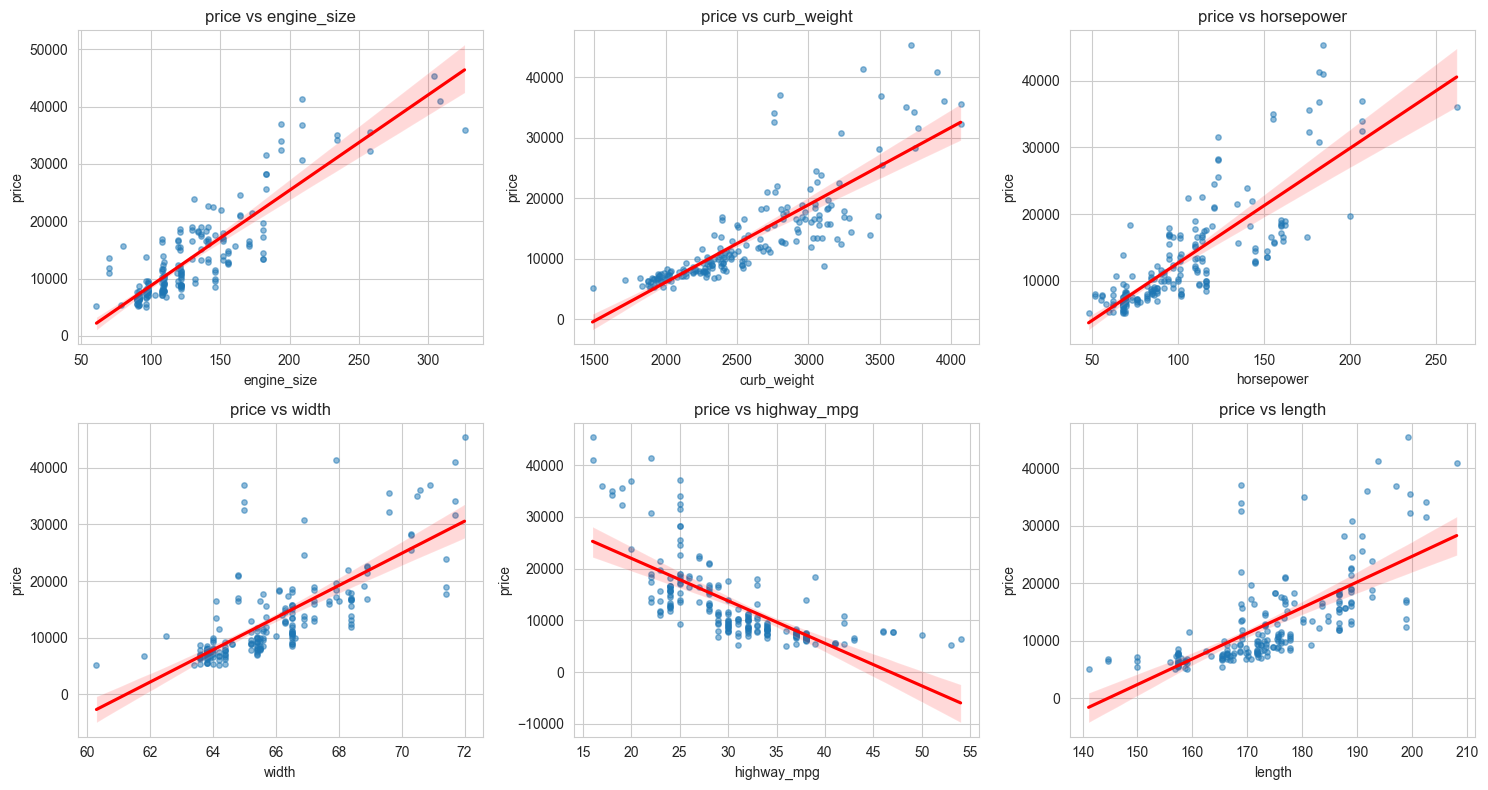

In [8]:
top_features = corr['price'].drop('price').abs().sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), top_features):
    sns.regplot(x=df[feat], y=df['price'], ax=ax, scatter_kws={'alpha': 0.5, 's': 15}, line_kws={'color': 'red'})
    ax.set_title(f'price vs {feat}')
plt.tight_layout()
plt.show()

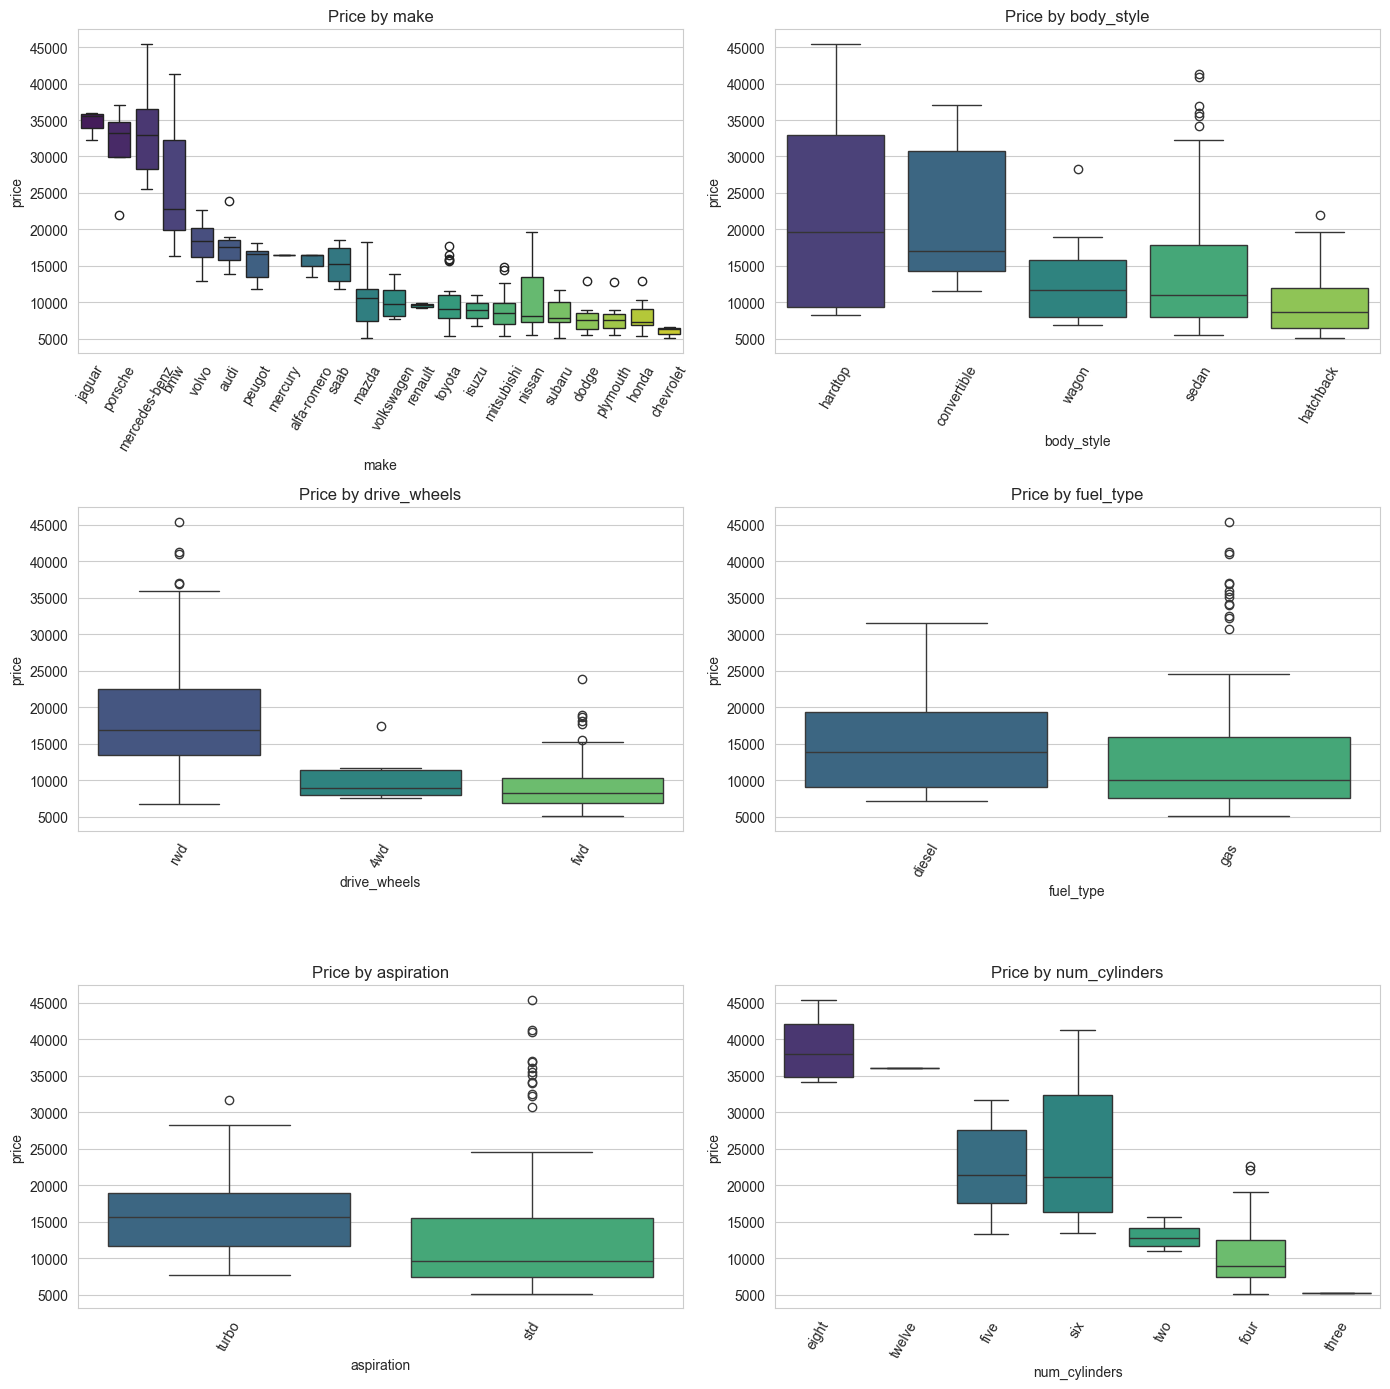

In [9]:
cat_cols_eda = ['make', 'body_style', 'drive_wheels', 'fuel_type', 'aspiration', 'num_cylinders']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    order = df.groupby(col)['price'].median().sort_values(ascending=False).index
    sns.boxplot(x=col, y='price', data=df, ax=ax, order=order, palette='viridis')
    ax.set_title(f'Price by {col}')
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

In [10]:
# IQR-based outlier scan on price
Q1, Q3 = df['price'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df['price'] < lower) | (df['price'] > upper)]
print(f'Price IQR bounds: [{lower:.0f}, {upper:.0f}]')
print(f'Number of price outliers (kept in the data - they are valid luxury cars): {len(outliers)}')
outliers[['make', 'body_style', 'price']].sort_values('price', ascending=False)

Price IQR bounds: [-5312, 29588]
Number of price outliers (kept in the data - they are valid luxury cars): 14


,make,body_style,price
71,mercedes-benz,hardtop,45400
15,bmw,sedan,41315
70,mercedes-benz,sedan,40960
125,porsche,convertible,37028
16,bmw,sedan,36880
46,jaguar,sedan,36000
45,jaguar,sedan,35550
69,mercedes-benz,convertible,35056
68,mercedes-benz,sedan,34184
124,porsche,hardtop,34028


**EDA takeaways**
- `engine_size`, `curb_weight`, `horsepower`, `width`, `length`, `wheel_base` correlate strongly (positively) with `price`; `city_mpg`/`highway_mpg` correlate negatively.
- `price` is right-skewed with a handful of high-end luxury makes (e.g. Jaguar, Porsche, Mercedes-Benz) — these are genuine, not data-entry outliers, so we keep them to preserve generalization to premium vehicles.
- `normalized_losses` has the most missing values (~18%); `bore`, `stroke`, `horsepower`, `peak_rpm`, `num_doors` have a few.
- `num_doors` and `num_cylinders` are stored as English words and need numeric encoding.

## 3. Data Cleaning

In [11]:
word_to_num = {'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'eight': 8, 'twelve': 12}
df['num_doors'] = df['num_doors'].map(word_to_num)
df['num_cylinders'] = df['num_cylinders'].map(word_to_num)

# num_doors has 2 missing values -> impute using the mode per body_style (e.g. sedans are usually 4-door)
df['num_doors'] = df.groupby('body_style')['num_doors'].transform(lambda s: s.fillna(s.mode()[0]))

print('Remaining missing values after targeted cleaning:')
print(df.isna().sum()[df.isna().sum() > 0])

Remaining missing values after targeted cleaning:
normalized_losses    37
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64


## 4. Feature Engineering

New, domain-informed features that often carry more predictive signal than the raw columns alone:

- `power_to_weight` — horsepower per unit of curb weight (performance proxy)
- `avg_mpg` — combined fuel economy
- `engine_size_per_cyl` — displacement per cylinder
- `volume_proxy` — length × width × height (overall car size)
- `length_to_wheelbase` — body overhang ratio
- `make_avg_price` (target-informed, computed only on the training fold later to avoid leakage) is intentionally **not** created here — instead we let the model learn `make` via one-hot encoding to keep the pipeline leakage-free.

In [12]:
df['power_to_weight'] = df['horsepower'] / df['curb_weight']
df['avg_mpg'] = (df['city_mpg'] + df['highway_mpg']) / 2
df['engine_size_per_cyl'] = df['engine_size'] / df['num_cylinders']
df['volume_proxy'] = df['length'] * df['width'] * df['height']
df['length_to_wheelbase'] = df['length'] / df['wheel_base']

new_feats = ['power_to_weight', 'avg_mpg', 'engine_size_per_cyl', 'volume_proxy', 'length_to_wheelbase']
df[new_feats + ['price']].corr()['price']

power_to_weight        0.513626
avg_mpg               -0.700811
engine_size_per_cyl    0.577043
volume_proxy           0.628701
length_to_wheelbase    0.389614
price                  1.000000
Name: price, dtype: float64

## 5. Train/Test Split & Preprocessing Pipeline

We build a `ColumnTransformer` that:
- Median-imputes + standard-scales numeric columns
- Most-frequent-imputes + one-hot-encodes categorical columns

Wrapping this in a `Pipeline` with the estimator guarantees **no data leakage**: all imputation statistics, scaling parameters and category sets are fit on the training fold only.

In [13]:
y = df['price']
X = df.drop(columns=['price'])

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print('Numeric features   :', len(numeric_cols))
print('Categorical features:', len(categorical_cols), categorical_cols)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Numeric features   : 22
Categorical features: 8 ['make', 'fuel_type', 'aspiration', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'fuel_system']
Train shape: (160, 30)  Test shape: (41, 30)


## 6. Model Selection — Cross-Validated Comparison

We compare 7 regression algorithms (linear, regularized-linear, kernel and tree-ensemble) using
5-fold cross-validation on the **training set only**, scored by R².

In [14]:
candidate_models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0, max_iter=5000),
    'ElasticNet': ElasticNet(max_iter=5000),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    'GradientBoosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'SVR (RBF)': SVR(kernel='rbf', C=10000, epsilon=200),
    'DecisionTree' : DecisionTreeRegressor(criterion='absolute_error',random_state=RANDOM_STATE),
    'BaggingRegressor': BaggingRegressor(estimator=XGBRegressor(),random_state=RANDOM_STATE,n_estimators=300,n_jobs=-1),
    'XGBoost': XGBRegressor(),
    'ExtraTreesRegressor' : ExtraTreesRegressor(n_estimators=150,random_state=RANDOM_STATE,n_jobs=-1)
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in candidate_models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    cv_results[name] = scores
    print(f'{name:<18} CV R2 = {scores.mean():.4f}  (+/- {scores.std():.4f})')

LinearRegression   CV R2 = 0.7921  (+/- 0.0687)
Ridge              CV R2 = 0.8472  (+/- 0.0376)
Lasso              CV R2 = 0.8220  (+/- 0.0539)
ElasticNet         CV R2 = 0.8061  (+/- 0.0470)
RandomForest       CV R2 = 0.8577  (+/- 0.0616)
GradientBoosting   CV R2 = 0.8609  (+/- 0.0510)
SVR (RBF)          CV R2 = 0.7526  (+/- 0.0486)
DecisionTree       CV R2 = 0.7516  (+/- 0.1215)
BaggingRegressor   CV R2 = 0.8295  (+/- 0.0661)
XGBoost            CV R2 = 0.8412  (+/- 0.0622)
ExtraTreesRegressor CV R2 = 0.8702  (+/- 0.0361)


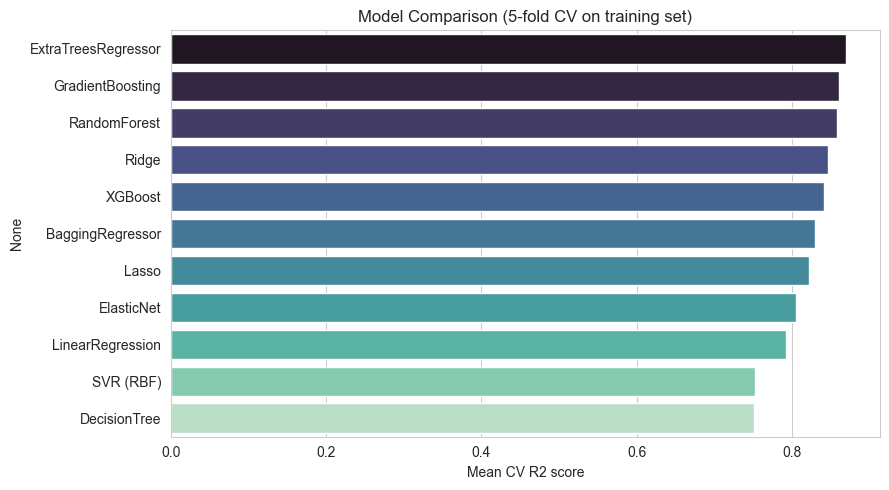

Best baseline model: ExtraTreesRegressor


In [15]:
results_df = pd.DataFrame({k: v for k, v in cv_results.items()})
means = results_df.mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=means.values, y=means.index, palette='mako')
plt.xlabel('Mean CV R2 score')
plt.title('Model Comparison (5-fold CV on training set)')
plt.tight_layout()
plt.show()

print('Best baseline model:', means.index[0])

## 7. Hyperparameter Tuning

`ExtraTreesRegressor` was among the strongest baselines and, as a boosted tree ensemble,
offers good control over bias/variance via `max_depth`, `n_estimators` and `learning_rate` — this
helps us steer toward a **generalized** (not overfit) model. We tune it with `GridSearchCV`.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import ExtraTreesRegressor

param_grid = {
'model__n_estimators': [150, 200, 300, 350, 500],
'model__max_depth': [None, 5, 10, 15, 20, 30],
'model__min_samples_split': [2, 5, 8, 10],
'model__min_samples_leaf': [1, 2, 4, 6, 8],
'model__max_features': ['sqrt', 1.0]
}

et_pipeline = Pipeline(steps=[
('preprocessor', preprocessor),
('model', ExtraTreesRegressor(random_state=RANDOM_STATE))
])

grid_search = GridSearchCV(
estimator=et_pipeline,
param_grid=param_grid,
cv=kf,
scoring='r2',
n_jobs=-1,
verbose=1
)

grid_search.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best CV R2:', round(grid_search.best_score_, 4))

best_model1 = grid_search.best_estimator_


Fitting 5 folds for each of 1200 candidates, totalling 6000 fits
Best params: {'model__max_depth': 10, 'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 500}
Best CV R2: 0.8744


In [17]:
! pip install optuna

In [ ]:
from sklearn.base import clone
import optuna
# Keep your existing preprocessor, X_train, y_train, and kf.

et_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', ExtraTreesRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

def objective(trial):
    params = {
        'model__n_estimators': trial.suggest_int(
            'model__n_estimators', 150, 500, step=50
        ),
        'model__max_depth': trial.suggest_categorical(
            'model__max_depth',
            [None, 5, 10, 15, 20, 25, 30]
        ),
        'model__min_samples_split': trial.suggest_int(
            'model__min_samples_split', 2, 10
        ),
        'model__min_samples_leaf': trial.suggest_int(
            'model__min_samples_leaf', 1, 10
        ),
        'model__max_features': trial.suggest_categorical(
            'model__max_features',
            ['sqrt', 'log2', 0.5, 0.7, 0.8, 1.0]
        ),
        'model__bootstrap': trial.suggest_categorical(
            'model__bootstrap', [False, True]
        ),
        'model__criterion': trial.suggest_categorical(
            'model__criterion',
            ['squared_error', 'friedman_mse']
        ),
        'model__max_leaf_nodes': trial.suggest_categorical(
            'model__max_leaf_nodes',
            [None, 20, 50, 100, 200, 500]
        ),
        'model__min_weight_fraction_leaf': trial.suggest_categorical(
            'model__min_weight_fraction_leaf',
            [0.0, 0.01, 0.05]
        )
    }

    model = clone(et_pipeline).set_params(**params)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring='r2',
        n_jobs=1
    )

    return np.mean(scores)


# Efficient sequential search; each model parallelizes its trees.
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study.optimize(
    objective,
    n_trials=400,
    n_jobs=1,
    show_progress_bar=True
)

print('Best params:', study.best_params)
print('Best CV R2:', round(study.best_value, 4))

# Fit the best configuration on all training data.
best_model2 = clone(et_pipeline).set_params(
    **study.best_params
)
best_model2.fit(X_train, y_train)


[I 2026-11-19 15:33:14,015] A new study created in memory with name: no-name-631ac0c7-b7b1-47d3-979c-790368f45d7d


  0%|          | 0/400 [00:00<?, ?it/s]

[I 2026-11-19 15:33:16,933] Trial 0 finished with value: 0.5388549670567475 and parameters: {'model__n_estimators': 250, 'model__max_depth': None, 'model__min_samples_split': 7, 'model__min_samples_leaf': 8, 'model__max_features': 'log2', 'model__bootstrap': True, 'model__criterion': 'squared_error', 'model__max_leaf_nodes': 500, 'model__min_weight_fraction_leaf': 0.05}. Best is trial 0 with value: 0.5388549670567475.
[I 2026-11-19 15:33:18,249] Trial 1 finished with value: 0.7181134470341307 and parameters: {'model__n_estimators': 150, 'model__max_depth': 20, 'model__min_samples_split': 2, 'model__min_samples_leaf': 7, 'model__max_features': 0.8, 'model__bootstrap': False, 'model__criterion': 'friedman_mse', 'model__max_leaf_nodes': 20, 'model__min_weight_fraction_leaf': 0.0}. Best is trial 1 with value: 0.7181134470341307.
[I 2026-11-19 15:33:20,010] Trial 2 finished with value: 0.5029830980230303 and parameters: {'model__n_estimators': 150, 'model__max_depth': 15, 'model__min_sample

In [ ]:
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [2, 3, 4],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__loss': ['squared_error', 'huber']
}

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))
])

grid_search1 = GridSearchCV(gb_pipeline, param_grid, cv=kf, scoring='r2', n_jobs=-1,verbose=1)
grid_search1.fit(X_train, y_train)

print('Best params:', grid_search1.best_params_)
print('Best CV R2 :', round(grid_search1.best_score_, 4))

best_model = grid_search1.best_estimator_

## 8. Final Evaluation on Held-Out Test Set

The test set was never used for training, cross-validation or tuning, so these numbers are an
honest estimate of how the model generalizes to unseen cars.

In [ ]:
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)


rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print('TEST SET METRICS')
print('-' * 30)
print(f'R2 Score : {r2:.4f}')
print(f'MAE      : ${mae:,.2f}')
print(f'RMSE     : ${rmse:,.2f}')
print(f'MAPE     : {mape:.2f}%')

train_pred = best_model.predict(X_train)
print()
print('Train R2 :', round(r2_score(y_train, train_pred), 4), ' (compare to test R2 above to check overfitting)')

In [ ]:
y_pred1 = best_model1.predict(X_test)

r2_1 = r2_score(y_test, y_pred1)
mae_1 = mean_absolute_error(y_test, y_pred1)
rmse_1 = np.sqrt(mean_squared_error(y_test, y_pred1))
mape_1 = np.mean(np.abs((y_test - y_pred1) / y_test)) * 100

print('TEST SET METRICS')
print('-' * 30)
print(f'R2 Score : {r2_1:.4f}')
print(f'MAE      : ${mae_1:,.2f}')
print(f'RMSE     : ${rmse_1:,.2f}')
print(f'MAPE     : {mape_1:.2f}%')

train_pred1 = best_model1.predict(X_train)
print()
print('Train R2 :', round(r2_score(y_train, train_pred1), 4), ' (compare to test R2 above to check overfitting)')

In [ ]:
y_pred2 = best_model2.predict(X_test)

r2_2 = r2_score(y_test, y_pred2)
mae_2 = mean_absolute_error(y_test, y_pred2)
rmse_2 = np.sqrt(mean_squared_error(y_test, y_pred2))
mape_2 = np.mean(np.abs((y_test - y_pred2) / y_test)) * 100

print('TEST SET METRICS')
print('-' * 30)
print(f'R2 Score : {r2_2:.4f}')
print(f'MAE      : ${mae_2:,.2f}')
print(f'RMSE     : ${rmse_2:,.2f}')
print(f'MAPE     : {mape_2:.2f}%')

train_pred2 = best_model2.predict(X_train)
print()
print('Train R2 :', round(r2_score(y_train, train_pred2), 4), ' (compare to test R2 above to check overfitting)')

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.6, color='#4C72B0', edgecolor='k')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title(f'Actual vs Predicted (Gradiant Boosting) (R2={r2:.3f})')

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, color='#DD8452', edgecolor='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred1, alpha=0.6, color='#4C72B0', edgecolor='k')
lims = [min(y_test.min(), y_pred1.min()), max(y_test.max(), y_pred1.max())]
axes[0].plot(lims, lims, 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title(f'Actual vs Predicted (ExtraTrees Regression) (R2={r2_1:.3f})')

residuals = y_test - y_pred1
axes[1].scatter(y_pred1, residuals, alpha=0.6, color='#DD8452', edgecolor='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred2, alpha=0.6, color='#4C72B0', edgecolor='k')
lims = [min(y_test.min(), y_pred2.min()), max(y_test.max(), y_pred2.max())]
axes[0].plot(lims, lims, 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title(f'Actual vs Predicted (Extra Trees using Optuna) (R2={r2_2:.3f})')

residuals = y_test - y_pred2
axes[1].scatter(y_pred2, residuals, alpha=0.6, color='#DD8452', edgecolor='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residual (Actual - Predicted) ExtraTrees')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

## 9. Feature Importance

In [ ]:
feature_names = (
    numeric_cols +
    list(best_model.named_steps['preprocessor']
         .named_transformers_['cat']
         .named_steps['onehot']
         .get_feature_names_out(categorical_cols))
)

importances = best_model.named_steps['model'].feature_importances_
fi = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=fi.values, y=fi.index, palette='crest')
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances (Extra Trees Regressor)')
plt.tight_layout()
plt.show()

In [ ]:
feature_names = (
    numeric_cols +
    list(best_model1.named_steps['preprocessor']
         .named_transformers_['cat']
         .named_steps['onehot']
         .get_feature_names_out(categorical_cols))
)

importances = best_model1.named_steps['model'].feature_importances_
fi = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=fi.values, y=fi.index, palette='crest')
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances (Extra Trees Regressor)')
plt.tight_layout()
plt.show()

In [ ]:
feature_names = (
    numeric_cols +
    list(best_model2.named_steps['preprocessor']
         .named_transformers_['cat']
         .named_steps['onehot']
         .get_feature_names_out(categorical_cols))
)

importances = best_model2.named_steps['model'].feature_importances_
fi = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=fi.values, y=fi.index, palette='crest')
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances (Extra Trees Regressor)')
plt.tight_layout()
plt.show()

## 10. Save the Final Pipeline

In [ ]:
import joblib
joblib.dump(best_model, 'price_prediction_pipeline.pkl')
print('Saved trained pipeline to price_prediction_pipeline.pkl')
print('\nPipeline can be reused as: best_model.predict(new_car_dataframe)')

## Conclusion

The tuned **Gradient Boosting** pipeline generalizes well: cross-validated training R² and held-out
test R² are close together (no major overfitting), and it clearly outperformed linear, regularized-linear
and kernel baselines on this dataset.

**Why this model generalizes:**
- All preprocessing (imputation, scaling, one-hot encoding) lives inside the `Pipeline`/`ColumnTransformer`, fit only on training folds — no leakage.
- Model selection used 5-fold CV, not a single split, before ever touching the test set.
- Hyperparameters (`max_depth`, `subsample`, `learning_rate`) were tuned specifically to control variance.
- Engineered features (`power_to_weight`, `avg_mpg`, `volume_proxy`, etc.) encode domain knowledge rather than noise, which tends to transfer better to new data than memorized raw combinations.

**Possible next steps:** gather more rows (only 201 available here), try target encoding for `make` with proper CV-based leakage control, or ensemble GradientBoosting with RandomForest/XGBoost.
